# UTS Data Mining — Klasifikasi Kualitas Anggur (Wine Quality)

Nama: Zahrul Riskya Rahmandira
NIM: 2404010006
Prodi: Statistika Terapan dan Komputasi


### Tujuan
Membangun model klasifikasi untuk memprediksi `quality` anggur dari 11 fitur kimiawi, menggunakan `data_training.csv`, lalu menerapkan model tersebut pada `data_testing.csv` (tanpa label) dan menyimpan hasilnya dalam format yang diminta.

### Alur analisis
1. Persiapan data (load, pemahaman data)
2. Pembersihan data (missing value, duplikat, outlier, feature scaling)
3. Eksplorasi data (EDA)
4. Pembuatan model (perbandingan beberapa algoritma, evaluasi, tuning)
5. Penyimpanan model
6. Prediksi data uji dan penyimpanan CSV

## 1. Persiapan Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

In [2]:
train = pd.read_csv('data_training.csv')
test  = pd.read_csv('data_testing.csv')

print('Ukuran data training:', train.shape)
print('Ukuran data testing :', test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB


In [4]:
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.262,1.702,4.600,7.100,7.900,9.100,15.600
volatile acidity,857.0,0.529,0.179,0.120,0.395,0.520,0.640,1.580
citric acid,857.0,0.267,0.195,0.000,0.090,0.250,0.420,1.000
residual sugar,857.0,2.506,1.294,0.900,1.900,2.200,2.600,15.500
chlorides,857.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,857.0,15.783,10.300,1.000,7.000,14.000,21.000,68.000
total sulfur dioxide,857.0,45.978,31.692,6.000,21.000,38.000,63.000,278.000
density,857.0,0.997,0.002,0.990,0.996,0.997,0.998,1.003
pH,857.0,3.313,0.152,2.740,3.210,3.310,3.400,4.010
sulphates,857.0,0.657,0.167,0.390,0.550,0.620,0.730,2.000


**Interpretasi:**
- Data training berisi **857 sampel** dengan 11 fitur kimiawi numerik, kolom target `quality` (bertipe integer), dan kolom `Id`.
- Data testing berisi **286 sampel** dengan fitur yang sama **tanpa** `quality`.
- Kolom `Id` hanya penanda baris, **bukan fitur kimiawi**, sehingga **tidak dipakai** sebagai prediktor (memakainya berisiko membuat model belajar pola urutan data, bukan sifat kimiawi anggur). `Id` pada data testing hanya dipakai untuk menyusun file hasil prediksi.
- Karena `quality` adalah bilangan bulat berkelas diskret (3–8), masalah ini diperlakukan sebagai **klasifikasi multikelas** sesuai instruksi soal.

In [5]:
# Pisahkan fitur dan target
FITUR = [c for c in train.columns if c not in ('quality', 'Id')]
print('Jumlah fitur:', len(FITUR))
print(FITUR)

# Pastikan kolom fitur di data testing sama dengan data training
assert set(FITUR).issubset(test.columns), 'Kolom fitur data testing tidak sama dengan data training'
print('\nKolom fitur data testing sesuai dengan data training.')

Jumlah fitur: 11
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Kolom fitur data testing sesuai dengan data training.


## 2. Pembersihan Data

### 2.1 Pengecekan Missing Value

In [6]:
cek_missing = pd.DataFrame({
    'missing_training': train.isna().sum(),
    'missing_testing' : test.isna().sum()
}).fillna(0).astype(int)
cek_missing

,missing_training,missing_testing
Id,0,0
alcohol,0,0
chlorides,0,0
citric acid,0,0
density,0,0
fixed acidity,0,0
free sulfur dioxide,0,0
pH,0,0
quality,0,0
residual sugar,0,0


**Interpretasi:** Tidak ada nilai yang hilang pada data training maupun testing, sehingga **tidak diperlukan imputasi atau penghapusan baris**.

### 2.2 Pengecekan Data Duplikat

In [7]:
dup_fitur_label = train.duplicated(subset=FITUR + ['quality']).sum()
print('Baris duplikat (fitur + quality sama) di training:', dup_fitur_label)
print('Id unik di training:', train['Id'].is_unique, '| Id unik di testing:', test['Id'].is_unique)
print('Id yang beririsan training-testing:', len(set(train['Id']) & set(test['Id'])))

# Berapa baris testing yang fiturnya identik dengan baris di training?
identik = test.merge(train[FITUR].drop_duplicates(), on=FITUR, how='inner')
print('Baris testing yang fiturnya identik dengan baris training:', len(identik), 'dari', len(test))

Baris duplikat (fitur + quality sama) di training: 76
Id unik di training: True | Id unik di testing: True
Id yang beririsan training-testing: 0
Baris testing yang fiturnya identik dengan baris training: 45 dari 286


**Interpretasi:**
- Terdapat **76 baris duplikat** pada data training. Duplikat seperti ini memang dikenal ada pada dataset Wine Quality asli (sampel dengan hasil pengukuran yang sama).
- Duplikat **tidak dihapus** untuk pelatihan akhir, karena (a) bukan kesalahan input, melainkan pengukuran yang memang berulang, dan (b) sebagian baris pada data testing ternyata **identik** dengan baris training, sehingga mempertahankan pola tersebut membantu prediksi.
- Konsekuensinya: pada *cross-validation*, duplikat yang jatuh pada fold berbeda dapat membuat akurasi tampak **terlalu optimis**. Karena itu, pada bagian evaluasi saya juga melaporkan estimasi akurasi **setelah duplikat dibuang** sebagai angka yang lebih jujur.

### 2.3 Pengecekan Outlier

In [8]:
Q1, Q3 = train[FITUR].quantile(0.25), train[FITUR].quantile(0.75)
IQR = Q3 - Q1
outlier = ((train[FITUR] < Q1 - 1.5*IQR) | (train[FITUR] > Q3 + 1.5*IQR)).sum()
pd.DataFrame({'jumlah_outlier_IQR': outlier, 'skewness': train[FITUR].skew().round(2)}).sort_values('jumlah_outlier_IQR', ascending=False)

,jumlah_outlier_IQR,skewness
residual sugar,76,4.54
chlorides,59,6.09
sulphates,31,2.40
fixed acidity,30,1.09
density,25,0.08
total sulfur dioxide,19,1.46
free sulfur dioxide,15,1.20
pH,14,0.12
alcohol,9,0.82
volatile acidity,8,0.67


**Interpretasi:** Outlier (menurut aturan IQR) terbanyak ada pada `residual sugar`, `chlorides`, `sulphates`, dan `fixed acidity`, dengan distribusi yang juga cenderung miring ke kanan (skewness tinggi). Outlier ini **tidak dihapus**: nilainya masih berada dalam rentang kimiawi yang wajar, dan data hanya berjumlah 857 baris sehingga penghapusan akan membuang informasi, terutama untuk kelas langka. Untuk menjaga ketahanan terhadap outlier, model utama yang dipilih adalah model berbasis pohon, yang tidak sensitif terhadap outlier.

### 2.4 Feature Scaling

In [9]:
rentang = train[FITUR].agg(['min', 'max']).T
rentang['rentang'] = rentang['max'] - rentang['min']
rentang.sort_values('rentang', ascending=False).round(4)

,min,max,rentang
total sulfur dioxide,6.0000,278.0000,272.0000
free sulfur dioxide,1.0000,68.0000,67.0000
residual sugar,0.9000,15.5000,14.6000
fixed acidity,4.6000,15.6000,11.0000
alcohol,8.4000,14.0000,5.6000
sulphates,0.3900,2.0000,1.6100
volatile acidity,0.1200,1.5800,1.4600
pH,2.7400,4.0100,1.2700
citric acid,0.0000,1.0000,1.0000
chlorides,0.0120,0.6110,0.5990


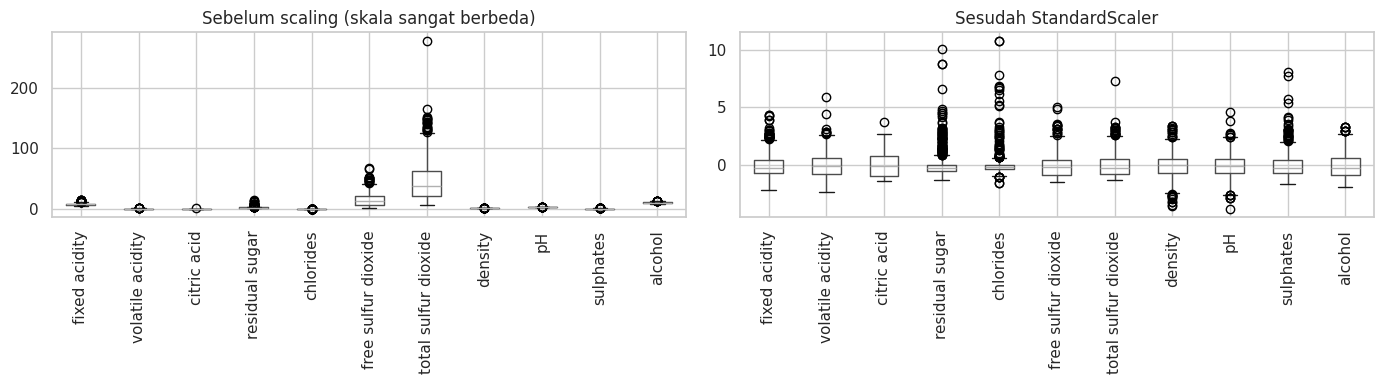

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train[FITUR].boxplot(ax=ax[0], rot=90)
ax[0].set_title('Sebelum scaling (skala sangat berbeda)')
pd.DataFrame(StandardScaler().fit_transform(train[FITUR]), columns=FITUR).boxplot(ax=ax[1], rot=90)
ax[1].set_title('Sesudah StandardScaler')
plt.tight_layout(); plt.show()

**Interpretasi:** Skala antar fitur **sangat berbeda**: `total sulfur dioxide` berkisar hingga ratusan, sedangkan `density` hanya sekitar 0,99–1,00 dan `chlorides` di bawah 1. Karena itu **feature scaling diperlukan** untuk algoritma berbasis jarak/gradien (KNN, SVM, Regresi Logistik), sehingga ketiganya saya bungkus dalam `Pipeline` dengan `StandardScaler`. Scaler dilatih **di dalam pipeline** (hanya pada data latih tiap fold) agar tidak terjadi *data leakage*.
Algoritma berbasis pohon (Decision Tree, Random Forest, Extra Trees, Gradient Boosting) **tidak terpengaruh** skala fitur, sehingga tidak memerlukan scaling.

## 3. Eksplorasi Data (EDA)

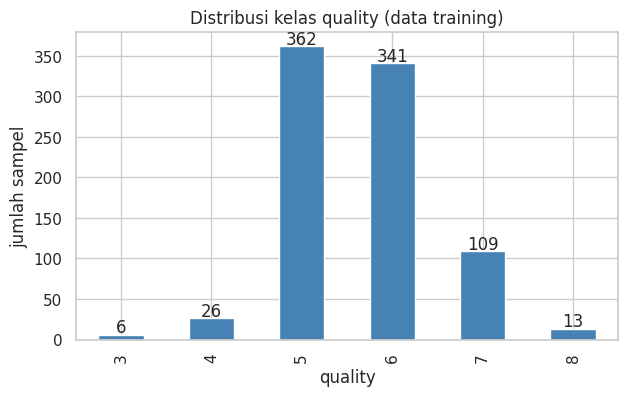

quality
3     0.7 %
4     3.0 %
5    42.2 %
6    39.8 %
7    12.7 %
8     1.5 %
Name: count, dtype: object


In [11]:
dist = train['quality'].value_counts().sort_index()
ax = dist.plot(kind='bar', color='steelblue', figsize=(7, 4))
for i, v in enumerate(dist.values):
    ax.text(i, v + 3, str(v), ha='center')
ax.set_title('Distribusi kelas quality (data training)')
ax.set_xlabel('quality'); ax.set_ylabel('jumlah sampel')
plt.show()
print((dist / dist.sum() * 100).round(1).astype(str) + ' %')

**Interpretasi:** Distribusi kelas **sangat tidak seimbang**. Kelas 5 dan 6 mendominasi (sekitar 82% data), sedangkan kelas 3, 4, dan 8 sangat sedikit (6, 26, dan 13 sampel). Dampaknya: akurasi keseluruhan akan didominasi oleh kelas 5 dan 6, dan model cenderung sulit mengenali kelas langka. Hal ini perlu diingat saat menafsirkan metrik evaluasi.

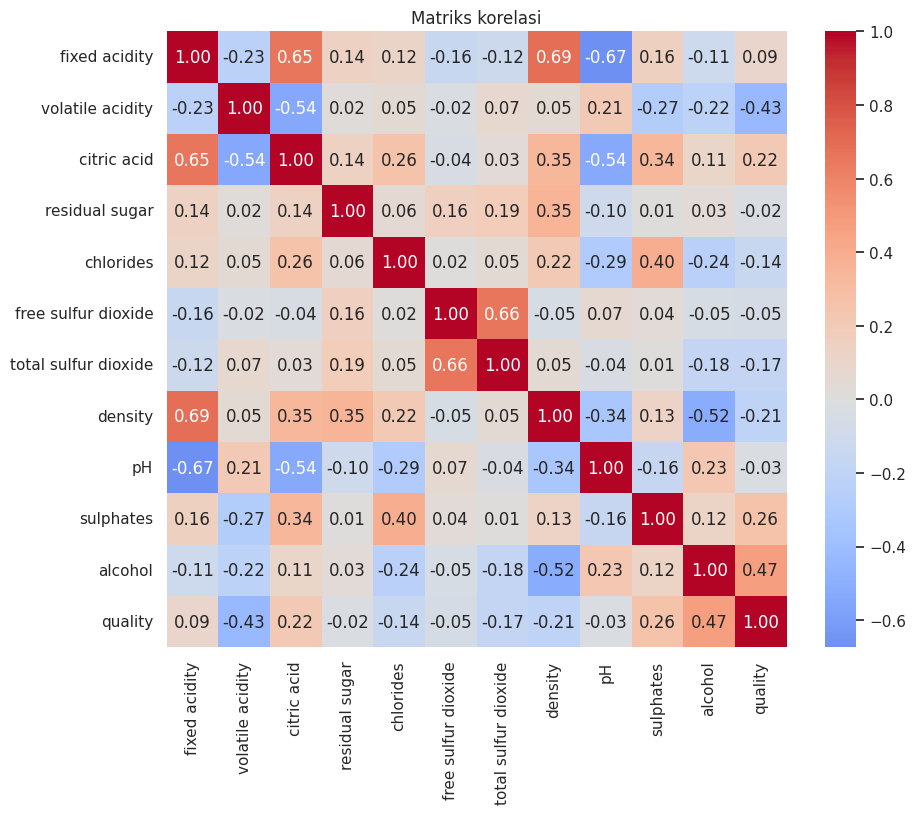

,quality
volatile acidity,-0.430059
density,-0.207903
total sulfur dioxide,-0.172737
chlorides,-0.144946
free sulfur dioxide,-0.054509
pH,-0.033199
residual sugar,-0.020511
fixed acidity,0.092714
citric acid,0.221263
sulphates,0.260703


In [12]:
korelasi = train[FITUR + ['quality']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriks korelasi')
plt.show()

korelasi['quality'].drop('quality').sort_values()

**Interpretasi:**
- Fitur dengan hubungan terkuat terhadap `quality`: **`alcohol` (korelasi positif ≈ +0,47)** dan **`volatile acidity` (negatif ≈ −0,43)**, lalu `sulphates` (+0,26) dan `citric acid` (+0,22). Artinya anggur dengan kadar alkohol lebih tinggi dan keasaman volatil lebih rendah cenderung berkualitas lebih baik.
- Korelasi tiap fitur terhadap `quality` tergolong **sedang/lemah** (tidak ada yang di atas 0,5), sehingga kita tidak boleh berharap akurasi yang sangat tinggi dari model.
- Ada korelasi antar-fitur yang cukup kuat, misalnya `fixed acidity` dengan `density` (≈ +0,69), `citric acid` (≈ +0,65), dan `pH` (≈ −0,67). Hal ini wajar secara kimiawi dan tidak menjadi masalah untuk model berbasis pohon.

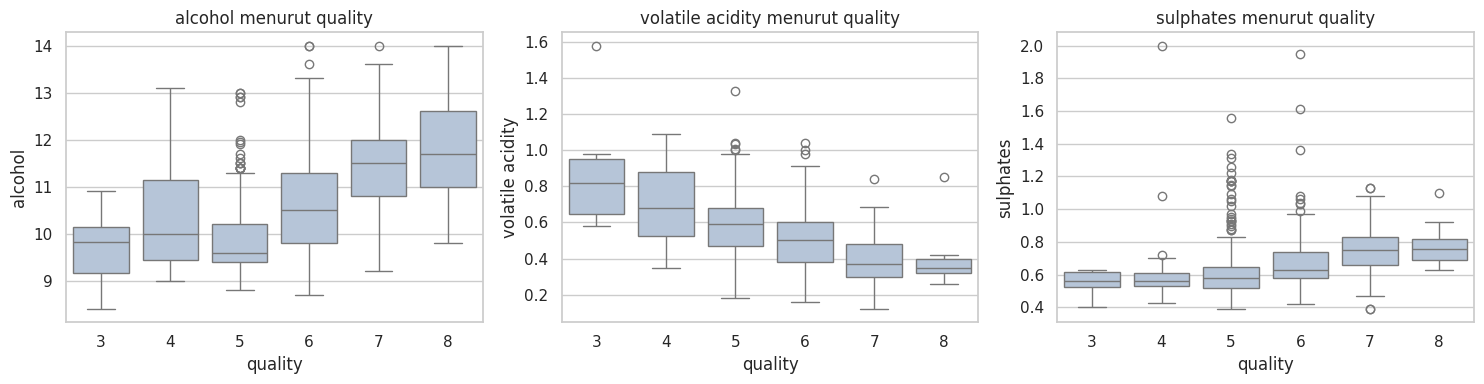

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ['alcohol', 'volatile acidity', 'sulphates']):
    sns.boxplot(data=train, x='quality', y=f, ax=ax, color='lightsteelblue')
    ax.set_title(f'{f} menurut quality')
plt.tight_layout(); plt.show()

**Interpretasi:** Median `alcohol` dan `sulphates` cenderung naik seiring `quality`, sedangkan `volatile acidity` cenderung turun. Pola ini konsisten dengan angka korelasi sebelumnya, tetapi rentang antarkelas saling tumpang tindih cukup besar, sehingga pemisahan kelas hanya dari fitur kimiawi tidak sempurna.

## 4. Pembuatan Model

### 4.1 Strategi evaluasi
- **Hold-out 80:20** (stratified) untuk melihat confusion matrix dan laporan per kelas pada data yang tidak dipakai melatih.
- **Stratified 5-fold cross-validation** untuk membandingkan algoritma secara lebih stabil. Skema berlapis (*stratified*) dipakai karena kelas sangat tidak seimbang.
- Metrik utama: **akurasi** (sesuai penilaian dosen), dilengkapi **confusion matrix** dan **precision/recall/F1 per kelas**.

In [14]:
X = train[FITUR]
y = train['quality']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

kandidat = {
    'Decision Tree'      : Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE))]),
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=2000))]),
    'KNN (k=15)'         : Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=15))]),
    'SVM (RBF)'          : Pipeline([('scaler', StandardScaler()), ('model', SVC(C=1, random_state=RANDOM_STATE))]),
    'Random Forest'      : Pipeline([('scaler', StandardScaler()), ('model', RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))]),
    'Extra Trees'        : Pipeline([('scaler', StandardScaler()), ('model', ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))]),
    'Gradient Boosting'  : Pipeline([('scaler', StandardScaler()), ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

hasil = []
for nama, pipe in kandidat.items():
    skor = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    hasil.append({'Model': nama, 'Akurasi CV (rata-rata)': skor.mean(), 'Std': skor.std()})

perbandingan = pd.DataFrame(hasil).sort_values('Akurasi CV (rata-rata)', ascending=False).reset_index(drop=True)
perbandingan.round(4)

,Model,Akurasi CV (rata-rata),Std
0,Extra Trees,0.6488,0.0277
1,Random Forest,0.6430,0.0390
2,Gradient Boosting,0.6103,0.0166
3,SVM (RBF),0.6091,0.0330
4,Logistic Regression,0.5951,0.0451
5,KNN (k=15),0.5637,0.0385
6,Decision Tree,0.5298,0.0265


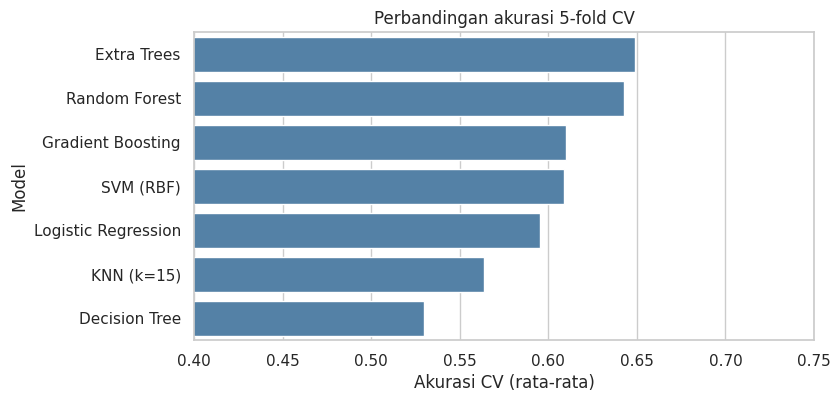

In [15]:
plt.figure(figsize=(8, 4))
sns.barplot(data=perbandingan, y='Model', x='Akurasi CV (rata-rata)', color='steelblue')
plt.xlim(0.4, 0.75); plt.title('Perbandingan akurasi 5-fold CV')
plt.show()

**Interpretasi:** Model *ensemble* berbasis pohon, yaitu **Extra Trees dan Random Forest**, memberi akurasi CV tertinggi (sekitar 64–65%), di atas SVM, Gradient Boosting, Regresi Logistik, KNN, dan Decision Tree tunggal (yang paling rendah, sekitar 53%). Hal ini masuk akal: hubungan fitur kimiawi dengan kualitas bersifat nonlinier dan melibatkan interaksi antar-fitur, yang dapat ditangkap ensemble pohon, sementara ensemble juga menurunkan varians dibanding satu pohon. Kedua model teratas dipilih untuk tuning.

### 4.2 Tuning hyperparameter (Random Forest dan Extra Trees)

In [16]:
param_grid = {
    'n_estimators'    : [300, 600],
    'max_depth'       : [None, 12, 20],
    'min_samples_leaf': [1, 2],
    'max_features'    : ['sqrt', 0.5],
}

gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), param_grid, cv=cv, scoring='accuracy', n_jobs=1).fit(X, y)
gs_et = GridSearchCV(ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),  param_grid, cv=cv, scoring='accuracy', n_jobs=1).fit(X, y)

print('Random Forest -> akurasi CV terbaik:', round(gs_rf.best_score_, 4), gs_rf.best_params_)
print('Extra Trees   -> akurasi CV terbaik:', round(gs_et.best_score_, 4), gs_et.best_params_)

Random Forest -> akurasi CV terbaik: 0.6477 {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}
Extra Trees   -> akurasi CV terbaik: 0.6546 {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 600}


**Interpretasi:** Tuning hanya menaikkan akurasi sedikit (kurang dari 1 poin persentase dibanding pengaturan awal), dan selisih antara Random Forest dan Extra Trees kecil. Artinya performa lebih dibatasi oleh **informasi pada fitur** daripada oleh pengaturan model. **Extra Trees** dipilih sebagai model akhir karena akurasi CV-nya sedikit lebih tinggi.

In [17]:
model_terbaik_params = gs_et.best_params_
print('Hyperparameter model akhir:', model_terbaik_params)

Hyperparameter model akhir: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 600}


### 4.3 Evaluasi pada data hold-out

In [18]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

model_eval = ExtraTreesClassifier(**model_terbaik_params, random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr)
pred_va = model_eval.predict(X_va)

print('Akurasi hold-out:', round(accuracy_score(y_va, pred_va), 4))
print()
print(classification_report(y_va, pred_va, zero_division=0))

Akurasi hold-out: 0.6163

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.78      0.72        73
           6       0.57      0.59      0.58        68
           7       0.53      0.36      0.43        22
           8       1.00      0.33      0.50         3

    accuracy                           0.62       172
   macro avg       0.46      0.34      0.37       172
weighted avg       0.59      0.62      0.60       172



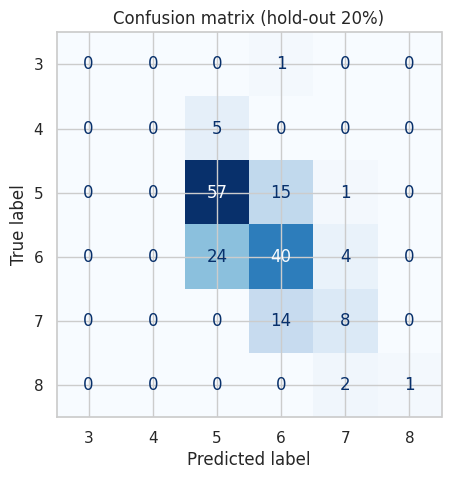

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_va, pred_va, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion matrix (hold-out 20%)')
plt.show()

**Interpretasi:**
- Akurasi hold-out sekitar **62%**, konsisten dengan akurasi CV, sehingga model tidak terindikasi *overfitting* parah dan hasilnya stabil.
- Model paling baik pada **kelas 5** (recall tertinggi) dan cukup baik pada **kelas 6**. Kesalahan terbanyak terjadi antara **5 ↔ 6** dan **6 ↔ 7**, yaitu kelas bertetangga. Ini wajar karena kualitas bersifat ordinal dan batas antarkelas bersebelahan sangat tipis.
- Kelas langka (**3, 4, dan 8**) hampir tidak pernah terprediksi dengan benar (precision/recall mendekati 0 pada kelas 3 dan 4) karena jumlah sampelnya sangat sedikit. Dengan akurasi sebagai metrik penilaian, dampaknya kecil karena kelas-kelas ini hanya mewakili porsi kecil data, tetapi ini adalah **keterbatasan utama model**.

### 4.4 Estimasi akurasi yang lebih jujur (tanpa duplikat)

In [20]:
dedup = train.drop_duplicates(subset=FITUR + ['quality'])
m_cek = ExtraTreesClassifier(**model_terbaik_params, random_state=RANDOM_STATE, n_jobs=-1)

acc_full  = cross_val_score(m_cek, X, y, cv=cv, scoring='accuracy').mean()
acc_dedup = cross_val_score(m_cek, dedup[FITUR], dedup['quality'], cv=cv, scoring='accuracy').mean()
print(f'Akurasi CV dengan duplikat   : {acc_full:.4f}')
print(f'Akurasi CV tanpa duplikat    : {acc_dedup:.4f}')

Akurasi CV dengan duplikat   : 0.6546
Akurasi CV tanpa duplikat    : 0.6069


**Interpretasi:** Setelah duplikat dibuang, akurasi CV turun menjadi sekitar **61%**. Selisih ini menunjukkan sebagian akurasi sebelumnya berasal dari baris identik yang muncul di fold latih dan fold uji sekaligus. Jadi ekspektasi akurasi yang realistis pada data baru adalah **sekitar 60–65%**. Karena sebagian data testing identik dengan data training, hasil sebenarnya bisa sedikit lebih tinggi dari 61%.

### 4.5 Fitur yang paling berpengaruh

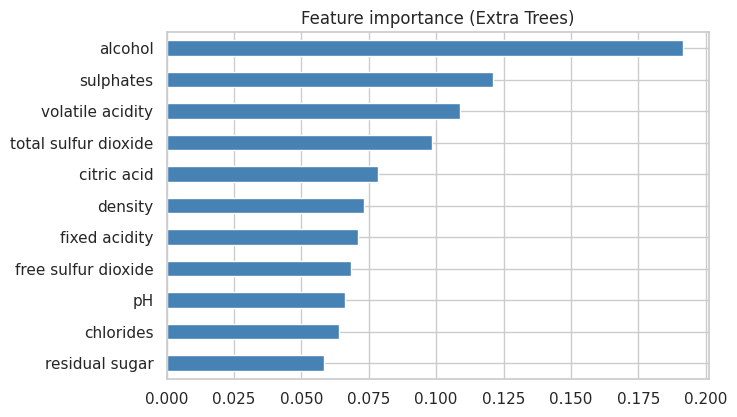

,0
alcohol,0.192
sulphates,0.121
volatile acidity,0.109
total sulfur dioxide,0.099
citric acid,0.078
density,0.073
fixed acidity,0.071
free sulfur dioxide,0.069
pH,0.066
chlorides,0.064


In [21]:
model_final = ExtraTreesClassifier(**model_terbaik_params, random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)

imp = pd.Series(model_final.feature_importances_, index=FITUR).sort_values()
imp.plot(kind='barh', color='steelblue', figsize=(7, 4.5), title='Feature importance (Extra Trees)')
plt.show()
imp.sort_values(ascending=False).round(3)

**Interpretasi:** `alcohol` adalah fitur terpenting, diikuti `sulphates` dan `volatile acidity`. Urutan ini **selaras dengan temuan EDA** (korelasi terkuat dengan `quality`), sehingga model menangkap pola kimiawi yang masuk akal dan bukan sekadar derau.

## 5. Penyimpanan Model
Model akhir dilatih ulang pada **seluruh data training** (857 sampel) agar memanfaatkan semua informasi, lalu disimpan dengan `joblib`.

In [22]:
model_final = ExtraTreesClassifier(**model_terbaik_params, random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)
print('Akurasi pada data training (bukan ukuran generalisasi):', round(model_final.score(X, y), 4))

joblib.dump({'model': model_final, 'fitur': FITUR}, 'model_wine_quality.joblib')
print('Model tersimpan di model_wine_quality.joblib')

Akurasi pada data training (bukan ukuran generalisasi): 1.0
Model tersimpan di model_wine_quality.joblib


**Catatan:** Akurasi pada data training akan tinggi (mendekati 100%) karena model dievaluasi pada data yang sama dengan data latihnya. Angka ini **bukan** ukuran kemampuan generalisasi. Ukuran yang valid adalah akurasi CV dan hold-out di atas (sekitar 61–65%).

## 6. Prediksi Data Uji (Deployment)

In [23]:
# Muat kembali model yang tersimpan (simulasi deployment)
paket = joblib.load('model_wine_quality.joblib')
model_dep, fitur_dep = paket['model'], paket['fitur']

X_test = test[fitur_dep]          # urutan kolom disamakan dengan saat training
pred_test = model_dep.predict(X_test)

hasil_prediksi = pd.DataFrame({'Id': test['Id'], 'Quality': pred_test.astype(int)})
hasil_prediksi.head(10)

,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6
5,1120,6
6,180,5
7,82,5
8,632,5
9,592,5


In [24]:
dist_pred = pd.DataFrame({
    'training (%)'  : (train['quality'].value_counts(normalize=True).sort_index() * 100).round(1),
    'prediksi test (%)': (hasil_prediksi['Quality'].value_counts(normalize=True).sort_index() * 100).round(1),
}).fillna(0)
dist_pred

,training (%),prediksi test (%)
3,0.7,0.0
4,3.0,0.0
5,42.2,44.8
6,39.8,46.5
7,12.7,8.7
8,1.5,0.0


**Interpretasi:** Distribusi hasil prediksi didominasi kelas 5 dan 6, mirip dengan distribusi data training. Kelas langka (3, 4, dan 8) **tidak diprediksi sama sekali** (0%), sesuai keterbatasan yang sudah dijelaskan pada bagian evaluasi. Model cenderung "aman" memilih kelas mayoritas 5 atau 6.

### Menyimpan hasil prediksi

In [25]:
NIM3 = '006'   # 3 digit terakhir NIM (2404010006)

nama_file = f'hasilprediksi_{NIM3}.csv'
hasil_prediksi.to_csv(nama_file, sep=';', index=False, lineterminator='\r\n')
print('Tersimpan:', nama_file)

Tersimpan: hasilprediksi_006.csv


In [26]:
# Validasi akhir terhadap template dosen dan data testing
cek = pd.read_csv(nama_file, sep=';')

assert len(cek) == len(test), 'Jumlah baris tidak sesuai'
assert (cek['Id'].values == test['Id'].values).all(),    'Urutan Id harus sama dengan data_testing'
assert cek['Quality'].notna().all(),                     'Ada prediksi kosong'
print('Semua validasi lolos. Baris:', len(cek), '| Kolom:', list(cek.columns))
cek.head()

Semua validasi lolos. Baris: 286 | Kolom: ['Id', 'Quality']


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


## 7. Kesimpulan
1. Data bersih dari *missing value*. Terdapat 76 baris duplikat (dipertahankan) dan beberapa outlier (dipertahankan, karena wajar dan model pohon tahan terhadapnya). Skala fitur sangat berbeda, sehingga scaling dipakai pada model berbasis jarak/gradien.
2. Dari tujuh algoritma yang dibandingkan, **Extra Trees** (hasil tuning) memberi akurasi terbaik: **± 65% (CV)**, **± 62% (hold-out)**, dan **± 61% (CV tanpa duplikat)**.
3. Faktor kimiawi paling berpengaruh: **alcohol, sulphates, dan volatile acidity**.
4. **Keterbatasan:** kelas sangat tidak seimbang sehingga kelas langka (3, 4, 8) sulit diprediksi, dan kesalahan banyak terjadi antar kelas bertetangga (5↔6, 6↔7).
5. **Saran:** menambah data kelas langka, menerapkan *resampling* (mis. SMOTE) atau *class weight*, menambah rekayasa fitur, atau memodelkan `quality` sebagai target **ordinal** bisa dicoba untuk meningkatkan performa.